# Financial News Sentiment and Stock Price Prediction

This notebook runs the project's methodology one stage at a time:

1. Data collection: prices from Yahoo Finance and headlines from Google News, stored in a SQLite database
2. Sentiment analysis: FinBERT classifies each headline as positive, negative or neutral
3. Feature engineering: RSI, MACD, SMA, EMA and volume indicators
4. Data integration: market features and daily sentiment merged into one dataset
5. Model training and tuning: LSTM and Transformer, with a hyperparameter search
6. Evaluation: MAE, RMSE and R², with and without sentiment
7. Explainability: SHAP feature contributions
8. Saving results for the dashboard (`streamlit run app.py`)

**Google Colab:** run the first cell. It downloads the project and installs its dependencies.

In [1]:
import sys

if "google.colab" in sys.modules:  # in Colab: download the project and install its dependencies
    !git clone -q https://github.com/Praisser/FinBERT.git /content/FinBERT
    %cd /content/FinBERT
    !pip install -q -r requirements.txt

In [2]:
%matplotlib inline
import logging
import warnings

import pandas as pd

warnings.filterwarnings("ignore", message="IProgress not found")  # progress-bar notice from a dependency

from stockpred import pipeline, plots

logging.basicConfig(format="%(asctime)s %(message)s", datefmt="%H:%M:%S")
logging.getLogger("stockpred").setLevel(logging.INFO)

TICKER = "AAPL"   # any Yahoo Finance symbol, e.g. MSFT or RELIANCE.NS
YEARS = 5

## 1–2. Data collection and FinBERT sentiment

Prices and headlines are saved to `data/market.db`. Running this again only fetches headlines that are not already stored, and only new headlines are scored with FinBERT.

In [3]:
prices, news, query = pipeline.collect_data(TICKER, YEARS)
print(f"{len(prices)} trading days, {len(news)} headlines for {query!r}")
prices.tail()

13:34:44 Downloading AAPL prices from 2021-11-07 to 2026-11-07


13:34:46 Collecting 'AAPL stock' headlines from 2026-10-31 to 2026-11-07


1255 trading days, 1912 headlines for 'AAPL stock'


,Open,High,Low,Close,Volume
date,,,,,
2026-11-02,342.670013,343.799988,335.820007,338.320007,64757700.0
2026-11-03,325.579987,334.500000,325.329987,331.899994,63160000.0
2026-11-04,341.570007,354.500000,340.989990,349.510010,89637700.0
2026-11-05,353.890015,355.380005,342.059998,344.170013,75678900.0
2026-11-06,338.730011,345.790009,338.299988,342.369995,44676300.0


In [4]:
news["label"].value_counts()

label
neutral     1169
negative     400
positive     343
Name: count, dtype: int64

In [5]:
news.sort_values("published", ascending=False).head(10)

,published,headline,positive,negative,neutral,label
1911,2026-11-07 03:12:00+00:00,Futures: Market Needs Repair; These Big Winner...,0.563694,0.036161,0.400144,positive
1910,2026-11-07 00:04:09+00:00,Apple Stock Price Forecast: AAPL Pulls Back Af...,0.239807,0.722903,0.037290,negative
1909,2026-11-06 22:51:00+00:00,If I Could Buy and Hold Only 1 Artificial Inte...,0.049287,0.012890,0.937822,neutral
1908,2026-11-06 20:34:00+00:00,Best Stocks to Buy Now: Our Buy-and-Hold Picks...,0.045091,0.019965,0.934944,neutral
1907,2026-11-06 19:49:21+00:00,Dan Ives: “20% of the World” Will Access AI Th...,0.104612,0.011392,0.883996,neutral
1906,2026-11-06 17:40:36+00:00,"15 Years Later, Siri Can “Finally” Do Its Job....",0.094993,0.075596,0.829411,neutral
1905,2026-11-06 17:37:31+00:00,"Apple Is “the Anti-AI Large Cap Tech Trade,” S...",0.093115,0.030178,0.876706,neutral
1904,2026-11-06 17:06:00+00:00,Stock Market Suffers Ugly Losses In Election W...,0.065397,0.866320,0.068283,negative
1903,2026-11-06 16:02:37+00:00,Apple stock price forecast: $358.66 resistance...,0.201850,0.080182,0.717968,neutral
1902,2026-11-06 14:54:00+00:00,US stock market today: Why is the Nasdaq up 1%...,0.636852,0.053079,0.310069,positive


## 3–4. Feature engineering and data integration

Each headline is assigned to the first trading session that closes after it was published. Sentiment is then averaged per day as positive minus negative probability.

In [6]:
data = pipeline.build_dataset(prices, news)
data.tail()

,Open,High,Low,Close,Volume,return,intraday,hl_range,volume_ratio,rsi,macd,macd_signal,close_vs_sma,close_vs_ema,sentiment,target
date,,,,,,,,,,,,,,,,
2026-11-02,342.670013,343.799988,335.820007,338.320007,64757700.0,-0.018479,-0.012776,0.023587,1.544478,47.876599,0.008936,0.011270,-0.011786,-0.010384,0.039649,-0.019159
2026-11-03,325.579987,334.500000,325.329987,331.899994,63160000.0,-0.019159,0.019226,0.027629,1.449818,41.704492,0.005661,0.010322,-0.030293,-0.026459,-0.390243,0.051699
2026-11-04,341.570007,354.500000,340.989990,349.510010,89637700.0,0.051699,0.022980,0.038654,1.934408,57.781936,0.006769,0.009196,0.019246,0.022741,-0.099328,-0.015396
2026-11-05,353.890015,355.380005,342.059998,344.170013,75678900.0,-0.015396,-0.027850,0.038702,1.565040,53.007873,0.006667,0.008804,0.003125,0.006433,0.164411,-0.005244
2026-11-06,338.730011,345.790009,338.299988,342.369995,44676300.0,-0.005244,0.010689,0.021877,0.917460,51.464315,0.006042,0.008289,-0.002954,0.001058,-0.016914,NaN


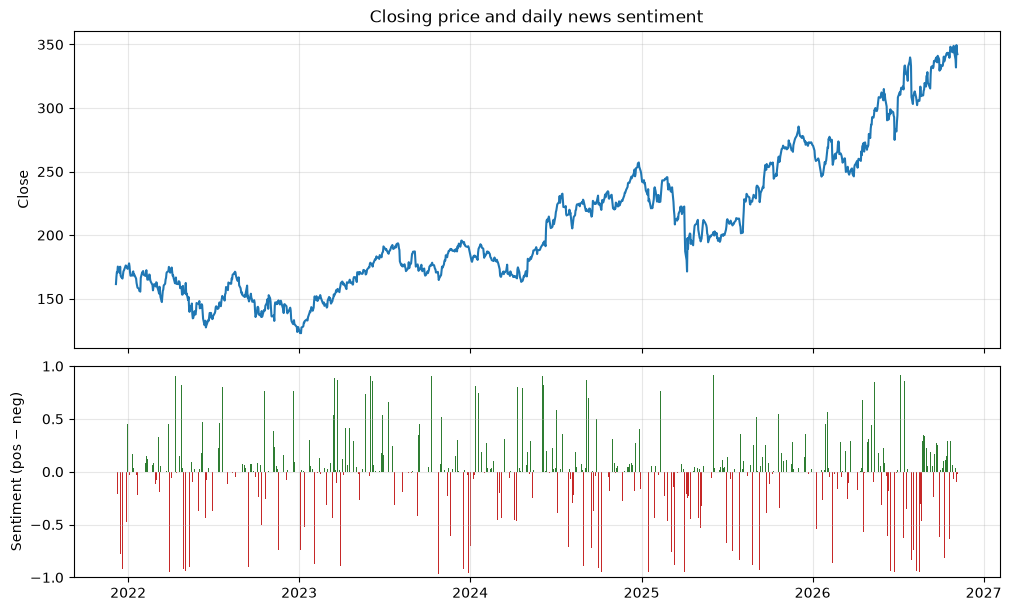

In [7]:
plots.sentiment_figure(data)

## 5–7. Tuning, training, evaluation and SHAP

Every setting in `SEARCH_SPACE` (in `stockpred/config.py`) is trained, and the one with the lowest validation loss is kept. Both models are also trained without the sentiment feature, to measure how much the news adds. This takes a few minutes.

In [8]:
results = pipeline.model_results(data)

13:34:47 Tuning LSTM (with sentiment)


13:34:52 Explaining LSTM predictions with SHAP


13:34:59 Tuning Transformer (with sentiment)


13:35:10 Explaining Transformer predictions with SHAP


13:35:12 Tuning LSTM (without sentiment)


13:35:17 Tuning Transformer (without sentiment)


In [9]:
tuning = pd.DataFrame(results.tuning)
tuning["params"] = tuning["params"].astype(str)
tuning

,model,features,params,val_loss,selected
0,LSTM,with sentiment,"{'hidden': 32, 'layers': 1}",0.580402,False
1,LSTM,with sentiment,"{'hidden': 32, 'layers': 2}",0.577282,False
2,LSTM,with sentiment,"{'hidden': 64, 'layers': 1}",0.574420,False
3,LSTM,with sentiment,"{'hidden': 64, 'layers': 2}",0.571368,True
4,Transformer,with sentiment,"{'d_model': 32, 'layers': 1}",0.615991,False
5,Transformer,with sentiment,"{'d_model': 32, 'layers': 2}",0.620145,False
6,Transformer,with sentiment,"{'d_model': 64, 'layers': 1}",0.579985,True
7,Transformer,with sentiment,"{'d_model': 64, 'layers': 2}",0.590062,False
8,LSTM,without sentiment,"{'hidden': 32, 'layers': 1}",0.579430,False
9,LSTM,without sentiment,"{'hidden': 32, 'layers': 2}",0.575384,False


In [10]:
pd.DataFrame(results.comparison).drop(columns="params").round(4)

,model,features,MAE,RMSE,R2
0,LSTM,with sentiment,3.6205,4.9689,0.9733
1,Transformer,with sentiment,3.7063,5.1152,0.9717
2,LSTM,without sentiment,3.6201,4.9791,0.9732
3,Transformer,without sentiment,3.6729,5.0395,0.9725


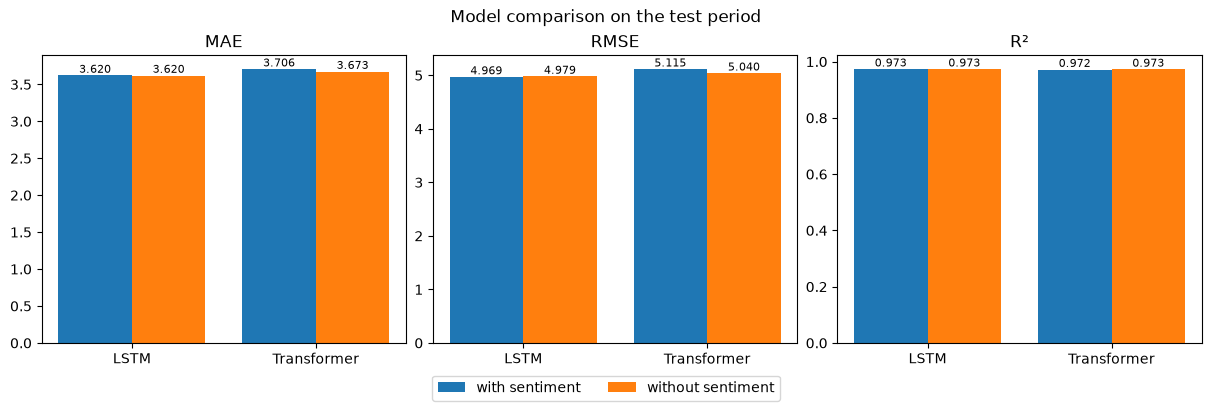

In [11]:
plots.comparison_figure(pd.DataFrame(results.comparison))

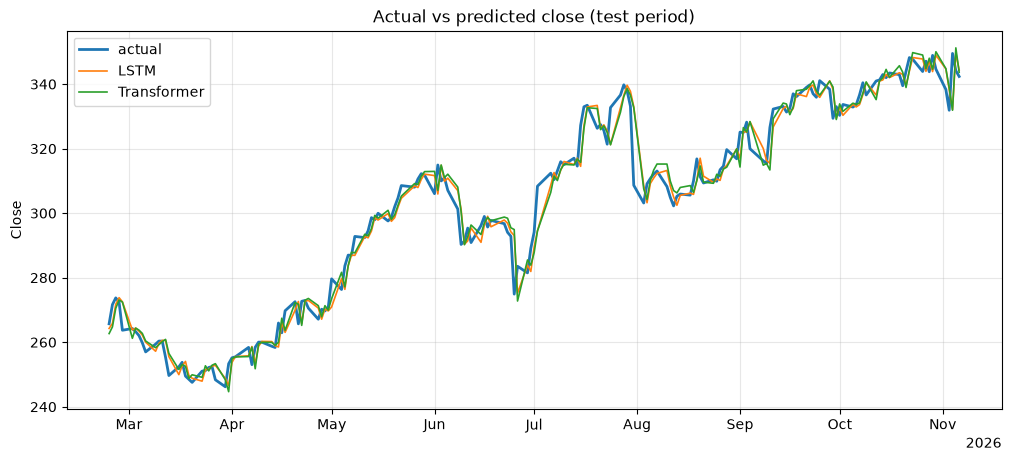

In [12]:
plots.prediction_figure(results.predictions)

{'LSTM': 342.58, 'Transformer': 342.8} next-day forecast


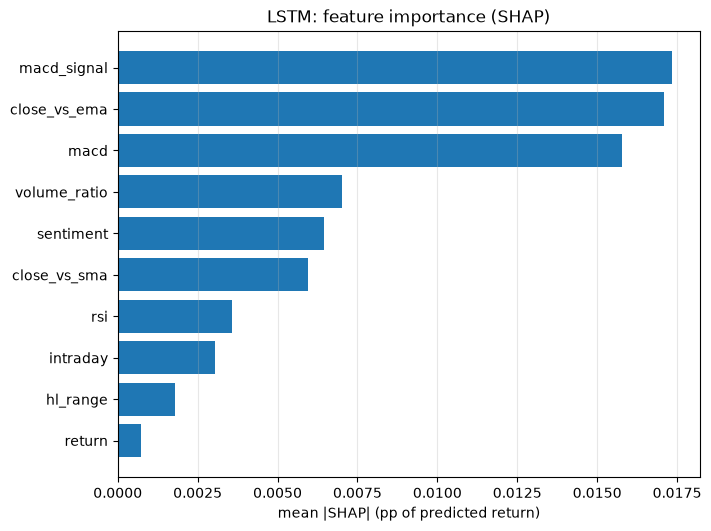

In [13]:
print({name: round(price, 2) for name, price in results.forecast.items()}, "next-day forecast")
plots.shap_figure(results.shap["LSTM"], "LSTM")

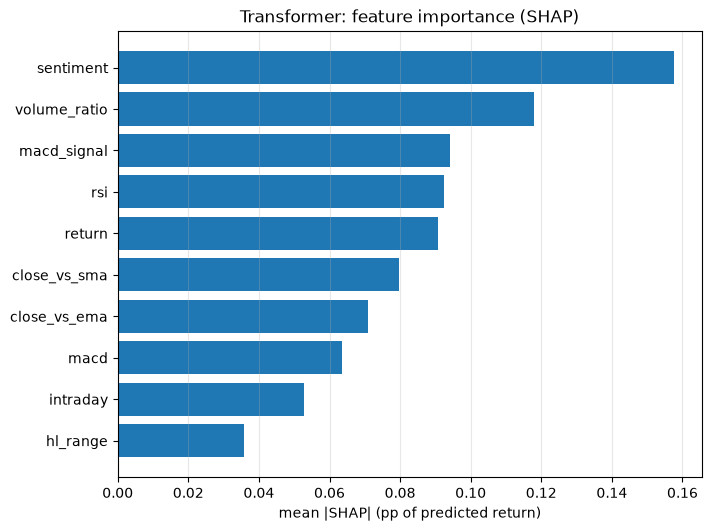

In [14]:
plots.shap_figure(results.shap["Transformer"], "Transformer")

## 8. Save results

Writes `artifacts/<TICKER>/` so the dashboard can display this run.

In [15]:
pipeline.save_results(TICKER, query, data, results)

PosixPath('/Users/praisser/Projects/apps/fepdel/artifacts/AAPL')